# Global Pollution Analysis and Energy Recovery

## Introduction

Pollution is one of the major environmental problems faced by countries around the world. Different types of pollution such as air, water, and soil pollution are affected by factors including industrial activities, energy consumption, waste generation, and economic development.

In this project, we analyze a global pollution dataset to understand the relationship between environmental factors, energy consumption, and energy recovery. Based on the pollution levels, the observations are divided into three categories: **Low, Medium, and High pollution severity**.

The project uses different machine learning classification techniques to predict the pollution severity category. The three models used are **Multinomial Naive Bayes, K-Nearest Neighbors (KNN), and Decision Tree**.

Along with classification, the project also studies energy recovery, industrial waste, CO₂ emissions, and renewable energy usage to identify useful environmental insights.

## Objectives

- Analyze and clean the global pollution dataset.
- Handle missing values, duplicate records, and outliers.
- Create a pollution index and classify observations into Low, Medium, and High severity.
- Prepare and scale the features required for machine learning.
- Apply Multinomial Naive Bayes, KNN, and Decision Tree classifiers.
- Tune the KNN and Decision Tree models using cross-validation.
- Compare the models using accuracy, precision, recall, F1-score, and confusion matrices.
- Study the relationship between pollution, industrial waste, renewable energy, and energy recovery.
- Identify useful findings and provide practical recommendations based on the analysis.

## Project Methodology

The project is divided into three main phases:

### Phase 1 – Data Preprocessing

The dataset is loaded and checked for missing values, duplicate records, and data types. Missing numerical values are handled using median values. The pollution indices are used to calculate an overall Pollution Index, which is then used to divide the observations into Low, Medium, and High pollution severity categories.

The data is then divided into training and testing sets. Outliers are handled using the IQR method based only on the training data, and the numerical features are scaled before applying the classification models.

### Phase 2 – Classification

Three classification algorithms are implemented:

1. **Multinomial Naive Bayes**
2. **K-Nearest Neighbors (KNN)**
3. **Decision Tree**

KNN is tuned by testing different values of K using 5-fold cross-validation. Similarly, the Decision Tree is tuned using different values of `max_depth` and `min_samples_split`.

The final models are evaluated on the test data using accuracy, precision, recall, F1-score, and confusion matrices.

### Phase 3 – Reporting and Insights

The performance of the three models is compared to understand how well the available environmental, energy, economic, and demographic features can classify pollution severity.

Additional analysis is performed on industrial waste, energy recovery, renewable energy, CO₂ emissions, country-wise pollution levels, and yearly trends.

## Important Note

The Air, Water, and Soil Pollution Index values are used to calculate the Pollution Index and define the pollution severity categories. Therefore, these three variables are not directly used as input features for the classification models. This avoids target leakage and gives a more meaningful evaluation of the models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
file_path = "Global_Pollution_Analysis.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (200, 13)


,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


In [3]:
print("Columns:")
for col in df.columns:
    print("-", col)

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Columns:
- Country
- Year
- Air_Pollution_Index
- Water_Pollution_Index
- Soil_Pollution_Index
- Industrial_Waste (in tons)
- Energy_Recovered (in GWh)
- CO2_Emissions (in MT)
- Renewable_Energy (%)
- Plastic_Waste_Produced (in tons)
- Energy_Consumption_Per_Capita (in MWh)
- Population (in millions)
- GDP_Per_Capita (in USD)

Dataset Shape: (200, 13)

Missing Values:
Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64

Duplicate Rows: 0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Country                                 200 non-null    str    
 1   Year                                    200 non-null    int64  
 2   Air_Pollution_Index                     200 non-null    float64
 3   Water_Pollution_Index                   200 non-null    float64
 4   Soil_Pollution_Index                    200 non-null    float64
 5   Industrial_Waste (in tons)              200 non-null    float64
 6   Energy_Recovered (in GWh)               200 non-null    float64
 7   CO2_Emissions (in MT)                   200 non-null    float64
 8   Renewable_Energy (%)                    200 non-null    float64
 9   Plastic_Waste_Produced (in tons)        200 non-null    float64
 10  Energy_Consumption_Per_Capita (in MWh)  200 non-null    float64
 11  Popu

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

df["Country"] = df["Country"].fillna("Unknown")

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [6]:
before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after = len(df)

print("Duplicates removed:", before - after)
print("New shape:", df.shape)

Duplicates removed: 0
New shape: (200, 13)


In [7]:
df["Pollution_Index"] = (
    df["Air_Pollution_Index"]
    + df["Water_Pollution_Index"]
    + df["Soil_Pollution_Index"]
) / 3

print(df["Pollution_Index"].describe())

count    200.000000
mean     124.061200
std       30.384136
min       42.546667
25%      102.122500
50%      124.995000
75%      145.312500
max      187.036667
Name: Pollution_Index, dtype: float64


In [8]:
df["Pollution_Severity"] = pd.qcut(
    df["Pollution_Index"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print(df["Pollution_Severity"].value_counts())

Pollution_Severity
Low       67
High      67
Medium    66
Name: count, dtype: int64


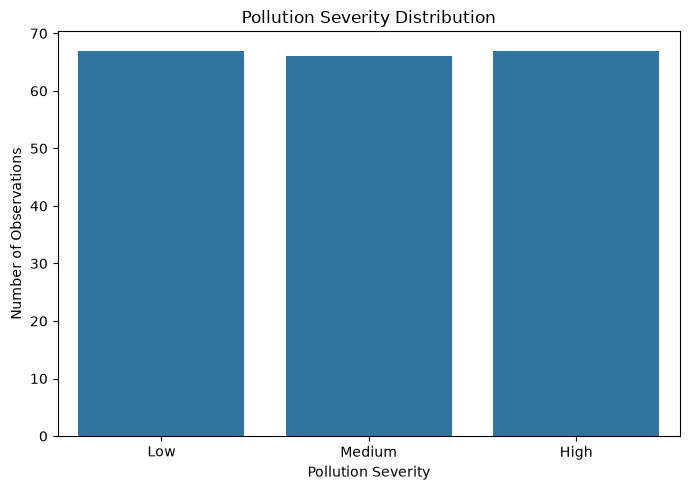

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Pollution_Severity"
)

plt.title("Pollution Severity Distribution")
plt.xlabel("Pollution Severity")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [10]:
country_values = sorted(df["Country"].astype(str).unique())

country_mapping = {
    country: index
    for index, country in enumerate(country_values)
}

df["Country_Encoded"] = (
    df["Country"]
    .astype(str)
    .map(country_mapping)
)

year_values = sorted(df["Year"].unique())

year_mapping = {
    year: index
    for index, year in enumerate(year_values)
}

df["Year_Encoded"] = df["Year"].map(year_mapping)

print(df[[
    "Country",
    "Country_Encoded",
    "Year",
    "Year_Encoded"
]].head())

        Country  Country_Encoded  Year  Year_Encoded
0       Hungary               77  2005             5
1     Singapore              147  2001             1
2       Romania              136  2016            16
3  Cook Islands               38  2018            18
4      Djibouti               46  2008             8


In [11]:
yearly_pollution = (
    df.groupby("Year")["Pollution_Index"]
    .mean()
    .reset_index()
)

yearly_pollution["Pollution_Trend"] = (
    yearly_pollution["Pollution_Index"]
    .diff()
)

yearly_pollution

,Year,Pollution_Index,Pollution_Trend
0,2000,128.530667,NaN
1,2001,97.745926,-30.784741
2,2002,124.541282,26.795356
3,2003,145.623333,21.082051
4,2004,120.599697,-25.023636
5,2005,120.307778,-0.291919
6,2006,137.652222,17.344444
7,2007,112.510606,-25.141616
8,2008,124.135238,11.624632
9,2009,122.824667,-1.310571


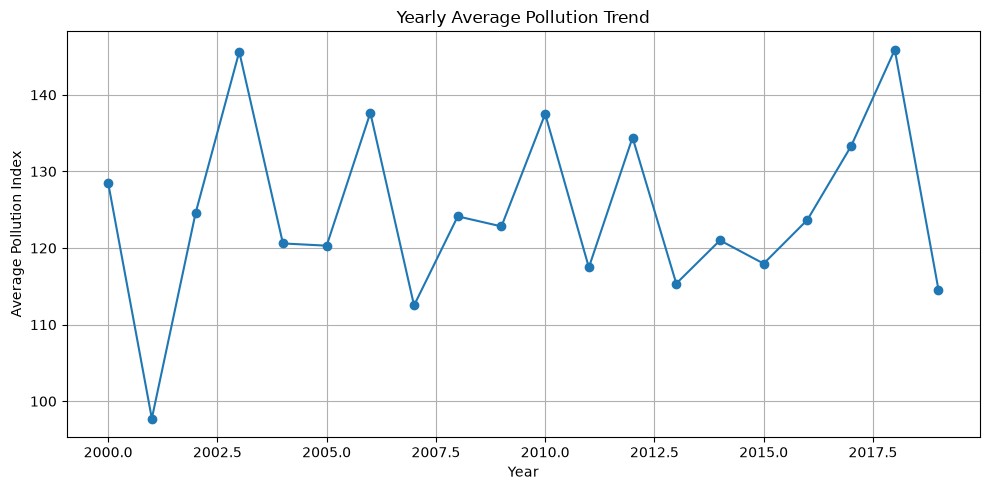

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_pollution["Year"],
    yearly_pollution["Pollution_Index"],
    marker="o"
)

plt.title("Yearly Average Pollution Trend")
plt.xlabel("Year")
plt.ylabel("Average Pollution Index")
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
feature_columns = [
    "Year",
    "Industrial_Waste (in tons)",
    "Energy_Recovered (in GWh)",
    "CO2_Emissions (in MT)",
    "Renewable_Energy (%)",
    "Plastic_Waste_Produced (in tons)",
    "Energy_Consumption_Per_Capita (in MWh)",
    "Population (in millions)",
    "GDP_Per_Capita (in USD)"
]

X = df[feature_columns].copy()

y = df["Pollution_Severity"].astype(str).copy()

print("Number of features:", X.shape[1])
print("\nFeatures used:")
for feature in feature_columns:
    print("-", feature)

Number of features: 9

Features used:
- Year
- Industrial_Waste (in tons)
- Energy_Recovered (in GWh)
- CO2_Emissions (in MT)
- Renewable_Energy (%)
- Plastic_Waste_Produced (in tons)
- Energy_Consumption_Per_Capita (in MWh)
- Population (in millions)
- GDP_Per_Capita (in USD)


In [14]:
print("Target classes:")
print(y.value_counts())

print("\nClass proportions:")
print(y.value_counts(normalize=True).round(3))

Target classes:
Pollution_Severity
High      67
Low       67
Medium    66
Name: count, dtype: int64

Class proportions:
Pollution_Severity
High      0.335
Low       0.335
Medium    0.330
Name: proportion, dtype: float64


In [15]:
np.random.seed(42)

train_indices = []
test_indices = []

for class_name in ["Low", "Medium", "High"]:

    class_indices = np.where(
        y.values == class_name
    )[0]

    np.random.shuffle(class_indices)

    split_point = int(len(class_indices) * 0.80)

    train_indices.extend(class_indices[:split_point])
    test_indices.extend(class_indices[split_point:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

np.random.shuffle(train_indices)
np.random.shuffle(test_indices)

X_train = X.iloc[train_indices].reset_index(drop=True)
X_test = X.iloc[test_indices].reset_index(drop=True)

y_train = y.iloc[train_indices].reset_index(drop=True)
y_test = y.iloc[test_indices].reset_index(drop=True)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 158
Testing samples: 42


In [16]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
Pollution_Severity
High      53
Low       53
Medium    52
Name: count, dtype: int64

Testing distribution:
Pollution_Severity
Medium    14
Low       14
High      14
Name: count, dtype: int64


In [17]:
outlier_bounds = {}

for col in X_train.columns:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower, upper)

print("Training-only IQR bounds calculated.")

Training-only IQR bounds calculated.


In [18]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for col in X_train.columns:

    lower, upper = outlier_bounds[col]

    X_train_clean[col] = X_train_clean[col].clip(
        lower=lower,
        upper=upper
    )

    X_test_clean[col] = X_test_clean[col].clip(
        lower=lower,
        upper=upper
    )

print("Outlier handling completed.")

Outlier handling completed.


In [19]:
train_medians = X_train_clean.median()

X_train_clean = X_train_clean.fillna(train_medians)
X_test_clean = X_test_clean.fillna(train_medians)

print("Missing values in training:", X_train_clean.isnull().sum().sum())
print("Missing values in testing:", X_test_clean.isnull().sum().sum())

Missing values in training: 0
Missing values in testing: 0


In [20]:
train_min = X_train_clean.min()
train_max = X_train_clean.max()

range_values = train_max - train_min

range_values = range_values.replace(0, 1)

X_train_scaled = (
    X_train_clean - train_min
) / range_values

X_test_scaled = (
    X_test_clean - train_min
) / range_values

X_train_scaled = X_train_scaled.clip(0, 1)
X_test_scaled = X_test_scaled.clip(0, 1)

print("Feature scaling completed.")

Feature scaling completed.


In [21]:
CLASS_LABELS = ["Low", "Medium", "High"]


def accuracy_score_manual(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return np.mean(y_true == y_pred)


def confusion_matrix_manual(y_true, y_pred):

    matrix = np.zeros(
        (len(CLASS_LABELS), len(CLASS_LABELS)),
        dtype=int
    )

    for actual, predicted in zip(y_true, y_pred):

        actual_index = CLASS_LABELS.index(actual)
        predicted_index = CLASS_LABELS.index(predicted)

        matrix[actual_index, predicted_index] += 1

    return matrix


def precision_recall_f1(y_true, y_pred):

    cm = confusion_matrix_manual(y_true, y_pred)

    precisions = []
    recalls = []
    f1_scores = []
    supports = []

    for i in range(len(CLASS_LABELS)):

        TP = cm[i, i]

        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP

        support = cm[i, :].sum()

        precision = (
            TP / (TP + FP)
            if (TP + FP) > 0
            else 0
        )

        recall = (
            TP / (TP + FN)
            if (TP + FN) > 0
            else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)
        supports.append(support)

    total_support = sum(supports)

    weighted_precision = sum(
        p * s
        for p, s in zip(precisions, supports)
    ) / total_support

    weighted_recall = sum(
        r * s
        for r, s in zip(recalls, supports)
    ) / total_support

    weighted_f1 = sum(
        f * s
        for f, s in zip(f1_scores, supports)
    ) / total_support

    return (
        weighted_precision,
        weighted_recall,
        weighted_f1
    )


def show_confusion_matrix(y_true, y_pred, title):

    cm = confusion_matrix_manual(y_true, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_LABELS,
        yticklabels=CLASS_LABELS
    )

    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

In [22]:
majority_class = y_train.value_counts().idxmax()

baseline_pred = np.array(
    [majority_class] * len(y_test)
)

baseline_accuracy = accuracy_score_manual(
    y_test,
    baseline_pred
)

print("Baseline Class:", majority_class)
print("Baseline Accuracy:", round(baseline_accuracy, 3))

Baseline Class: High
Baseline Accuracy: 0.333


In [23]:
def train_multinomial_nb(X, y, alpha=1.0):

    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    classes = CLASS_LABELS

    class_log_prior = {}
    feature_log_prob = {}

    for class_name in classes:

        X_class = X[y == class_name]

        class_count = len(X_class)

        class_log_prior[class_name] = np.log(
            class_count / len(y)
        )

        feature_sum = X_class.sum(axis=0)

        feature_log_prob[class_name] = np.log(
            (feature_sum + alpha)
            /
            (feature_sum.sum() + alpha * X.shape[1])
        )

    return class_log_prior, feature_log_prob

In [24]:
def predict_multinomial_nb(
    X,
    class_log_prior,
    feature_log_prob
):

    X = np.asarray(X, dtype=float)

    predictions = []

    for row in X:

        scores = {}

        for class_name in CLASS_LABELS:

            score = (
                class_log_prior[class_name]
                + np.sum(
                    row *
                    feature_log_prob[class_name]
                )
            )

            scores[class_name] = score

        prediction = max(
            scores,
            key=scores.get
        )

        predictions.append(prediction)

    return np.array(predictions)

In [25]:
nb_prior, nb_prob = train_multinomial_nb(
    X_train_scaled,
    y_train.values
)

nb_pred = predict_multinomial_nb(
    X_test_scaled,
    nb_prior,
    nb_prob
)

nb_accuracy = accuracy_score_manual(
    y_test,
    nb_pred
)

nb_precision, nb_recall, nb_f1 = precision_recall_f1(
    y_test,
    nb_pred
)

print("Multinomial Naive Bayes")
print("-----------------------")
print("Accuracy :", round(nb_accuracy, 3))
print("Precision:", round(nb_precision, 3))
print("Recall   :", round(nb_recall, 3))
print("F1 Score :", round(nb_f1, 3))

Multinomial Naive Bayes
-----------------------
Accuracy : 0.238
Precision: 0.221
Recall   : 0.238
F1 Score : 0.227


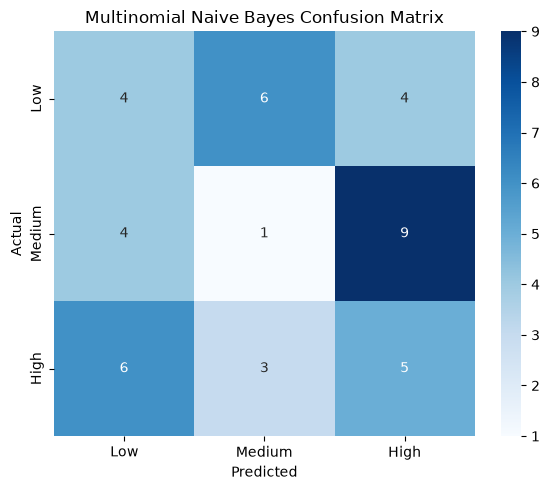

In [26]:
show_confusion_matrix(
    y_test,
    nb_pred,
    "Multinomial Naive Bayes Confusion Matrix"
)

In [27]:
def euclidean_distance(row1, row2):

    return np.sqrt(
        np.sum((row1 - row2) ** 2)
    )


def knn_predict(X_train, y_train, X_test, k):

    X_train = np.asarray(X_train, dtype=float)
    X_test = np.asarray(X_test, dtype=float)
    y_train = np.asarray(y_train)

    predictions = []

    for test_row in X_test:

        distances = []

        for i, train_row in enumerate(X_train):

            distance = euclidean_distance(
                test_row,
                train_row
            )

            distances.append(
                (distance, y_train[i])
            )

        distances.sort(
            key=lambda x: x[0]
        )

        nearest_labels = [
            label
            for _, label
            in distances[:k]
        ]

        counts = {}

        for label in nearest_labels:
            counts[label] = counts.get(label, 0) + 1

        prediction = max(
            counts,
            key=counts.get
        )

        predictions.append(prediction)

    return np.array(predictions)

In [28]:
def create_stratified_folds(y, n_folds=5, seed=42):

    y = np.asarray(y)

    rng = np.random.default_rng(seed)

    folds = [
        []
        for _ in range(n_folds)
    ]

    for class_name in CLASS_LABELS:

        indices = np.where(
            y == class_name
        )[0]

        rng.shuffle(indices)

        for i, index in enumerate(indices):

            folds[i % n_folds].append(index)

    return [
        np.array(sorted(fold))
        for fold in folds
    ]

In [29]:
knn_k_values = [1, 3, 5, 7, 9, 11, 13, 15]

folds = create_stratified_folds(
    y_train.values,
    n_folds=5,
    seed=42
)

knn_cv_results = []

for k in knn_k_values:

    fold_scores = []

    for fold_number in range(5):

        validation_indices = folds[fold_number]

        training_indices = np.concatenate([
            folds[i]
            for i in range(5)
            if i != fold_number
        ])

        X_cv_train = X_train_scaled.iloc[
            training_indices
        ]

        y_cv_train = y_train.iloc[
            training_indices
        ]

        X_cv_valid = X_train_scaled.iloc[
            validation_indices
        ]

        y_cv_valid = y_train.iloc[
            validation_indices
        ]

        cv_pred = knn_predict(
            X_cv_train,
            y_cv_train,
            X_cv_valid,
            k
        )

        score = accuracy_score_manual(
            y_cv_valid,
            cv_pred
        )

        fold_scores.append(score)

    knn_cv_results.append({
        "K": k,
        "CV_Accuracy": np.mean(fold_scores)
    })

knn_cv_results = pd.DataFrame(
    knn_cv_results
)

knn_cv_results

,K,CV_Accuracy
0,1,0.356023
1,3,0.361288
2,5,0.349735
3,7,0.391932
4,9,0.372538
5,11,0.333788
6,13,0.341439
7,15,0.356402


In [30]:
best_k = int(
    knn_cv_results.loc[
        knn_cv_results["CV_Accuracy"].idxmax(),
        "K"
    ]
)

print("Best K:", best_k)

print(
    "Best CV Accuracy:",
    round(
        knn_cv_results["CV_Accuracy"].max(),
        3
    )
)

Best K: 7
Best CV Accuracy: 0.392


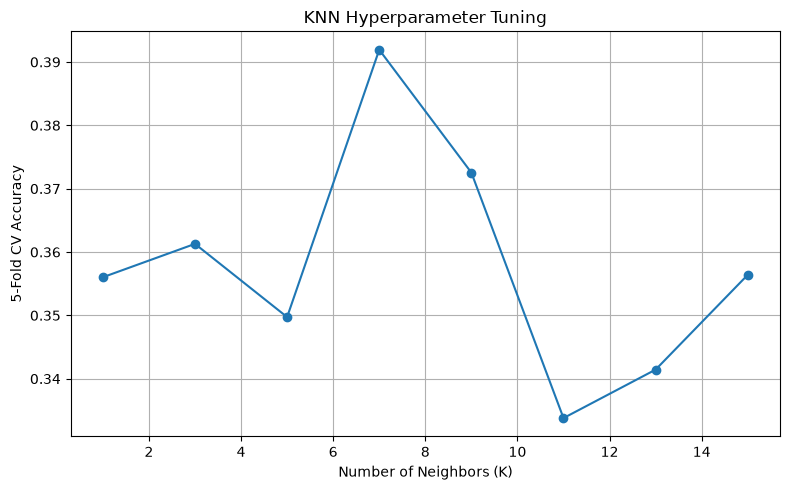

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_cv_results["K"],
    knn_cv_results["CV_Accuracy"],
    marker="o"
)

plt.title("KNN Hyperparameter Tuning")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("5-Fold CV Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
knn_pred = knn_predict(
    X_train_scaled,
    y_train,
    X_test_scaled,
    best_k
)

knn_accuracy = accuracy_score_manual(
    y_test,
    knn_pred
)

knn_precision, knn_recall, knn_f1 = precision_recall_f1(
    y_test,
    knn_pred
)

print("KNN")
print("---")
print("Best K   :", best_k)
print("Accuracy :", round(knn_accuracy, 3))
print("Precision:", round(knn_precision, 3))
print("Recall   :", round(knn_recall, 3))
print("F1 Score :", round(knn_f1, 3))

KNN
---
Best K   : 7
Accuracy : 0.357
Precision: 0.372
Recall   : 0.357
F1 Score : 0.358


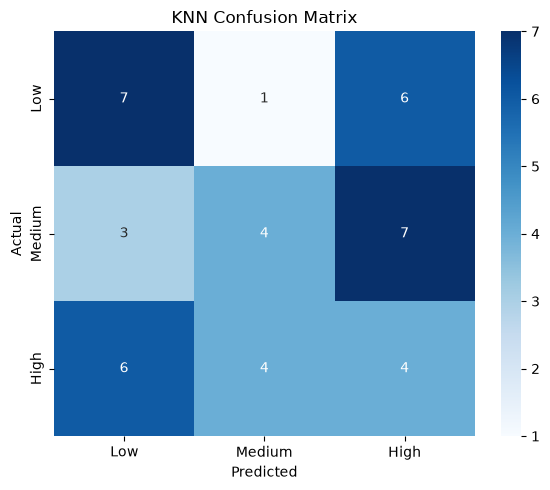

In [33]:
show_confusion_matrix(
    y_test,
    knn_pred,
    "KNN Confusion Matrix"
)

In [34]:
def gini_score(y):

    y = np.asarray(y)

    if len(y) == 0:
        return 0

    _, counts = np.unique(
        y,
        return_counts=True
    )

    probabilities = counts / len(y)

    return 1 - np.sum(
        probabilities ** 2
    )

In [35]:
def dt_find_split(X, y):

    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    best_feature_index = None
    best_threshold = None
    best_gini_value = float("inf")

    for feature_index in range(X.shape[1]):

        values = np.unique(
            X[:, feature_index]
        )

        for threshold in values:

            left_mask = (
                X[:, feature_index] <= threshold
            )

            right_mask = (
                X[:, feature_index] > threshold
            )

            left_y = y[left_mask]
            right_y = y[right_mask]

            if len(left_y) == 0:
                continue

            if len(right_y) == 0:
                continue

            left_gini = gini_score(left_y)
            right_gini = gini_score(right_y)

            total = len(y)

            weighted_gini = (
                (len(left_y) / total) * left_gini
                +
                (len(right_y) / total) * right_gini
            )

            if weighted_gini < best_gini_value:

                best_gini_value = weighted_gini
                best_feature_index = feature_index
                best_threshold = threshold

    return (
        best_feature_index,
        best_threshold,
        best_gini_value
    )

In [36]:
def dt_majority_class(y):

    values, counts = np.unique(
        y,
        return_counts=True
    )

    return values[
        np.argmax(counts)
    ]

In [37]:
def dt_build_tree(
    X,
    y,
    depth=0,
    max_depth=5,
    min_samples_split=10
):

    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    node = {}

    # Stopping conditions
    if len(np.unique(y)) == 1:

        node["leaf"] = True
        node["class"] = dt_majority_class(y)

        return node

    if depth >= max_depth:

        node["leaf"] = True
        node["class"] = dt_majority_class(y)

        return node

    if len(y) < min_samples_split:

        node["leaf"] = True
        node["class"] = dt_majority_class(y)

        return node

    # Find best split
    feature_index, threshold, gini_value = dt_find_split(
        X,
        y
    )

    if feature_index is None:

        node["leaf"] = True
        node["class"] = dt_majority_class(y)

        return node

    left_mask = (
        X[:, feature_index] <= threshold
    )

    right_mask = (
        X[:, feature_index] > threshold
    )

    node["leaf"] = False
    node["feature"] = feature_index
    node["threshold"] = threshold

    node["left"] = dt_build_tree(
        X[left_mask],
        y[left_mask],
        depth + 1,
        max_depth,
        min_samples_split
    )

    node["right"] = dt_build_tree(
        X[right_mask],
        y[right_mask],
        depth + 1,
        max_depth,
        min_samples_split
    )

    return node

In [38]:
def dt_predict_one(node, row):

    if node["leaf"]:
        return node["class"]

    if row[node["feature"]] <= node["threshold"]:

        return dt_predict_one(
            node["left"],
            row
        )

    return dt_predict_one(
        node["right"],
        row
    )


def dt_predict(tree, X):

    X = np.asarray(X, dtype=float)

    predictions = []

    for row in X:

        predictions.append(
            dt_predict_one(tree, row)
        )

    return np.array(predictions)

In [39]:
depth_values = [3, 5, 7, 10]
split_values = [2, 5, 10]

tree_cv_results = []

for depth_value in depth_values:

    for split_value in split_values:

        fold_scores = []

        for fold_number in range(5):

            validation_indices = folds[
                fold_number
            ]

            training_indices = np.concatenate([
                folds[i]
                for i in range(5)
                if i != fold_number
            ])

            X_cv_train = X_train_scaled.iloc[
                training_indices
            ]

            y_cv_train = y_train.iloc[
                training_indices
            ]

            X_cv_valid = X_train_scaled.iloc[
                validation_indices
            ]

            y_cv_valid = y_train.iloc[
                validation_indices
            ]

            temporary_tree = dt_build_tree(
                np.array(X_cv_train),
                np.array(y_cv_train),
                max_depth=depth_value,
                min_samples_split=split_value
            )

            cv_pred = dt_predict(
                temporary_tree,
                np.array(X_cv_valid)
            )

            score = accuracy_score_manual(
                y_cv_valid,
                cv_pred
            )

            fold_scores.append(score)

        tree_cv_results.append({
            "max_depth": depth_value,
            "min_samples_split": split_value,
            "CV_Accuracy": np.mean(fold_scores)
        })

tree_cv_results = pd.DataFrame(
    tree_cv_results
)

tree_cv_results

,max_depth,min_samples_split,CV_Accuracy
0,3,2,0.371780
1,3,5,0.371780
2,3,10,0.371780
3,5,2,0.312462
4,5,5,0.318712
5,5,10,0.324962
6,7,2,0.374242
7,7,5,0.380076
8,7,10,0.374205
9,10,2,0.348409


In [40]:
best_tree_row = tree_cv_results.loc[
    tree_cv_results["CV_Accuracy"].idxmax()
]

best_tree_depth = int(
    best_tree_row["max_depth"]
)

best_tree_split = int(
    best_tree_row["min_samples_split"]
)

best_tree_cv_accuracy = (
    best_tree_row["CV_Accuracy"]
)

print(
    "Best max_depth:",
    best_tree_depth
)

print(
    "Best min_samples_split:",
    best_tree_split
)

print(
    "Best CV Accuracy:",
    round(
        best_tree_cv_accuracy,
        3
    )
)

Best max_depth: 7
Best min_samples_split: 5
Best CV Accuracy: 0.38


In [41]:
final_tree = dt_build_tree(
    np.array(X_train_scaled),
    np.array(y_train),
    max_depth=best_tree_depth,
    min_samples_split=best_tree_split
)

tree_pred = dt_predict(
    final_tree,
    np.array(X_test_scaled)
)

tree_accuracy = accuracy_score_manual(
    y_test,
    tree_pred
)

tree_precision, tree_recall, tree_f1 = precision_recall_f1(
    y_test,
    tree_pred
)

print("Decision Tree")
print("-------------")
print("Max Depth:", best_tree_depth)
print("Min Samples Split:", best_tree_split)
print("Accuracy :", round(tree_accuracy, 3))
print("Precision:", round(tree_precision, 3))
print("Recall   :", round(tree_recall, 3))
print("F1 Score :", round(tree_f1, 3))

Decision Tree
-------------
Max Depth: 7
Min Samples Split: 5
Accuracy : 0.262
Precision: 0.264
Recall   : 0.262
F1 Score : 0.262


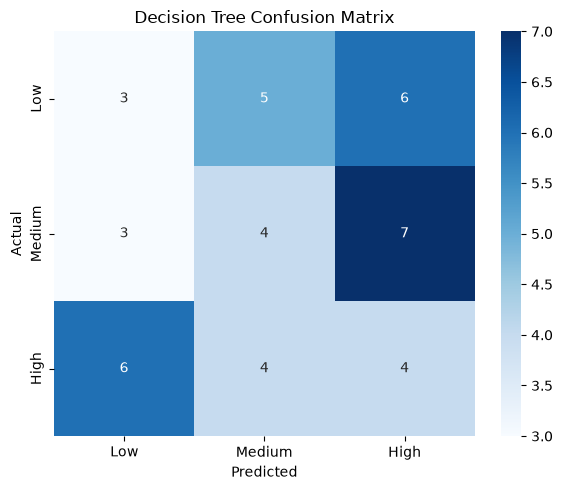

In [42]:
show_confusion_matrix(
    y_test,
    tree_pred,
    "Decision Tree Confusion Matrix"
)

In [43]:
comparison = pd.DataFrame({

    "Model": [
        "Baseline",
        "Multinomial Naive Bayes",
        "KNN",
        "Decision Tree"
    ],

    "Accuracy": [
        baseline_accuracy,
        nb_accuracy,
        knn_accuracy,
        tree_accuracy
    ],

    "Precision": [
        np.nan,
        nb_precision,
        knn_precision,
        tree_precision
    ],

    "Recall": [
        np.nan,
        nb_recall,
        knn_recall,
        tree_recall
    ],

    "F1 Score": [
        np.nan,
        nb_f1,
        knn_f1,
        tree_f1
    ]
})

comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.333,NaN,NaN,NaN
1,Multinomial Naive Bayes,0.238,0.221,0.238,0.227
2,KNN,0.357,0.372,0.357,0.358
3,Decision Tree,0.262,0.264,0.262,0.262


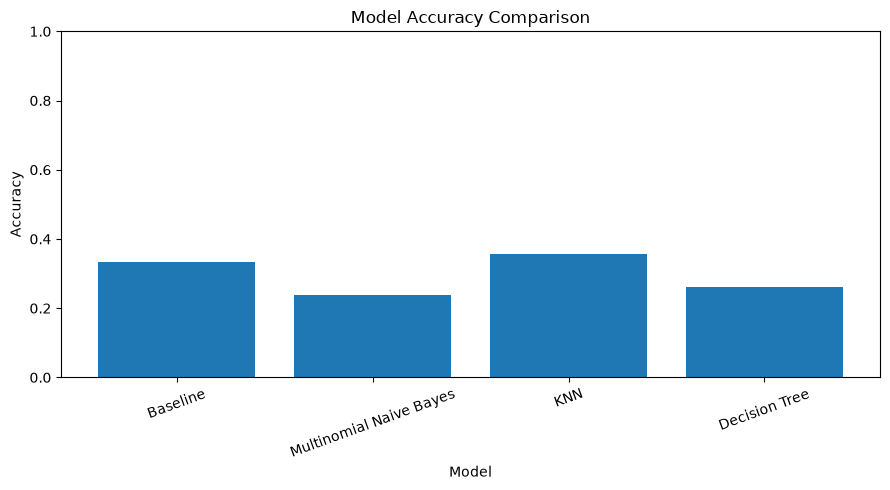

In [44]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

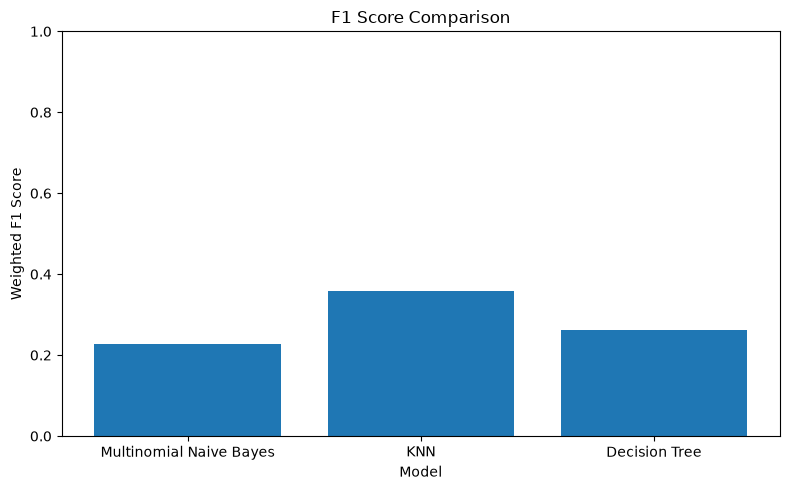

In [45]:
f1_comparison = comparison.dropna(
    subset=["F1 Score"]
)

plt.figure(figsize=(8, 5))

plt.bar(
    f1_comparison["Model"],
    f1_comparison["F1 Score"]
)

plt.title("F1 Score Comparison")
plt.xlabel("Model")
plt.ylabel("Weighted F1 Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

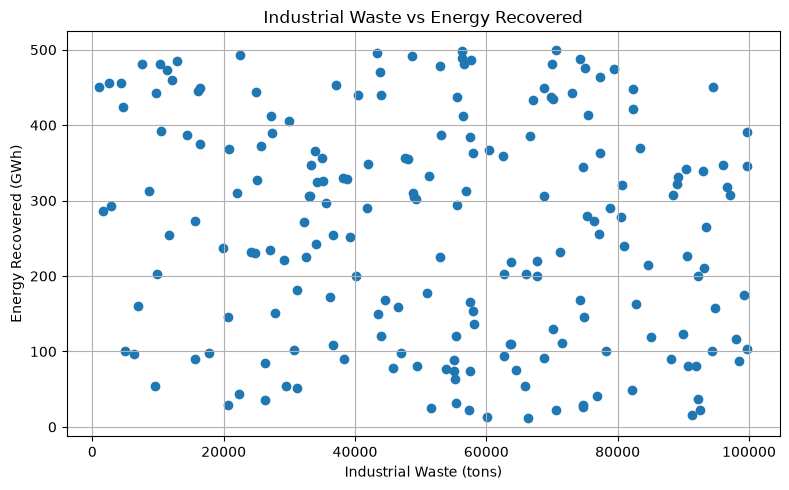

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Industrial_Waste (in tons)"],
    df["Energy_Recovered (in GWh)"]
)

plt.title(
    "Industrial Waste vs Energy Recovered"
)

plt.xlabel(
    "Industrial Waste (tons)"
)

plt.ylabel(
    "Energy Recovered (GWh)"
)

plt.grid(True)
plt.tight_layout()
plt.show()

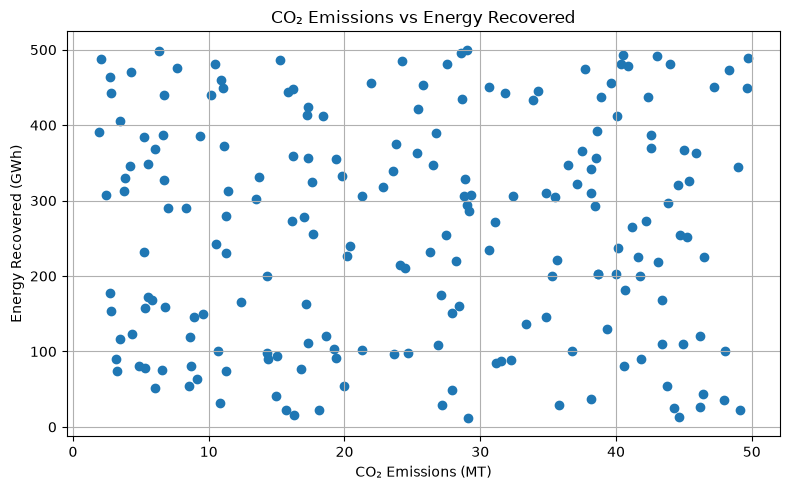

In [47]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["CO2_Emissions (in MT)"],
    df["Energy_Recovered (in GWh)"]
)

plt.title(
    "CO₂ Emissions vs Energy Recovered"
)

plt.xlabel(
    "CO₂ Emissions (MT)"
)

plt.ylabel(
    "Energy Recovered (GWh)"
)

plt.grid(True)
plt.tight_layout()
plt.show()

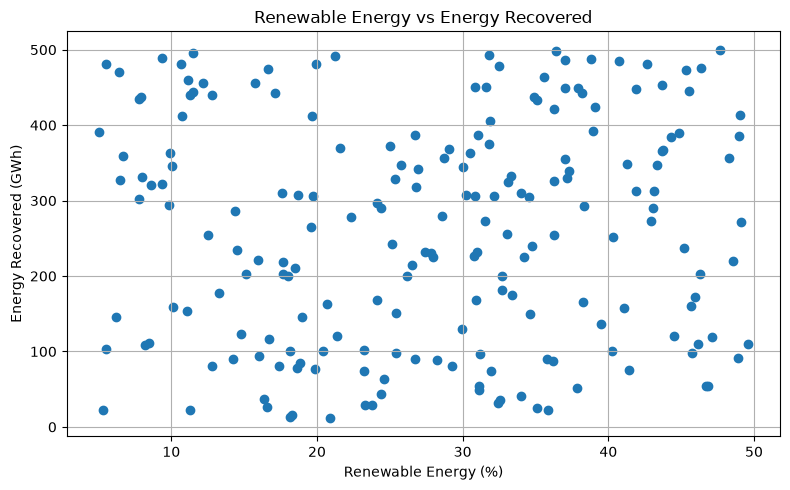

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Renewable_Energy (%)"],
    df["Energy_Recovered (in GWh)"]
)

plt.title(
    "Renewable Energy vs Energy Recovered"
)

plt.xlabel(
    "Renewable Energy (%)"
)

plt.ylabel(
    "Energy Recovered (GWh)"
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
top_10_countries = (
    df.groupby("Country")["Pollution_Index"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by average pollution index:")
print(top_10_countries)

Top 10 countries by average pollution index:
Country
Saint Barthelemy            187.036667
Bolivia                     181.496667
Central African Republic    177.016667
Christmas Island            175.950000
Papua New Guinea            175.660000
Guinea-Bissau               175.353333
Morocco                     174.250000
Philippines                 173.636667
Saint Lucia                 173.626667
Argentina                   173.093333
Name: Pollution_Index, dtype: float64


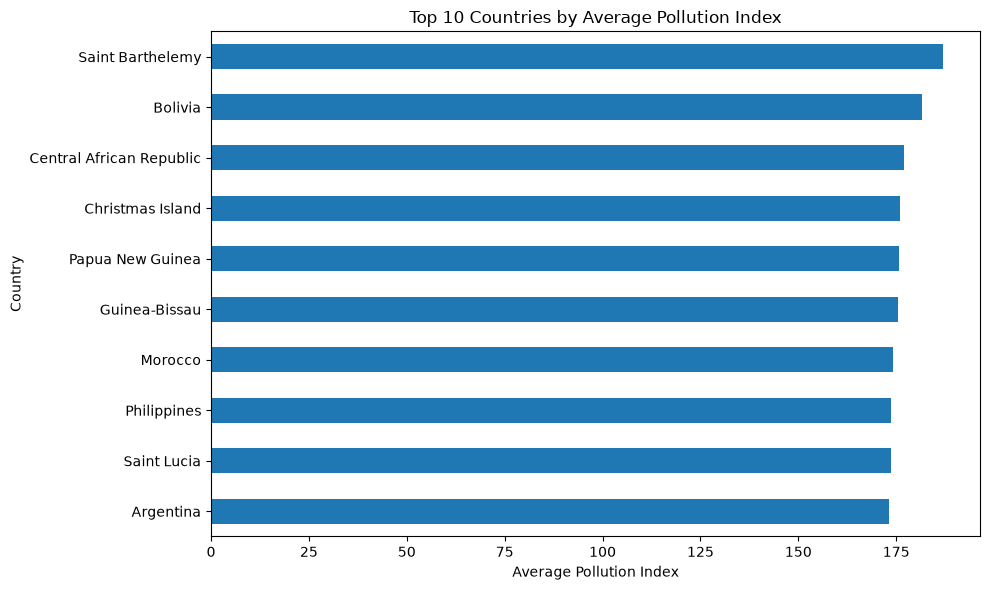

In [50]:
plt.figure(figsize=(10, 6))

top_10_countries.sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 10 Countries by Average Pollution Index"
)

plt.xlabel("Average Pollution Index")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

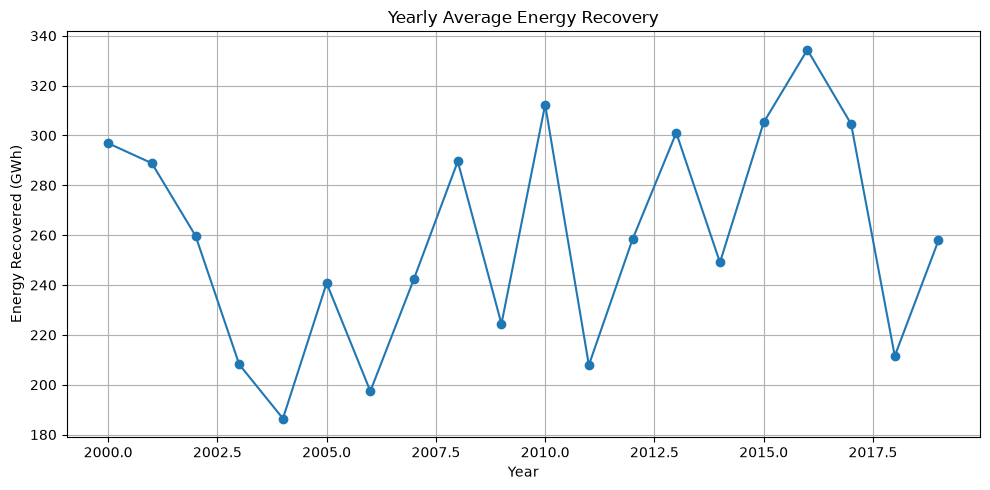

In [51]:
yearly_energy = (
    df.groupby("Year")["Energy_Recovered (in GWh)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_energy["Year"],
    yearly_energy["Energy_Recovered (in GWh)"],
    marker="o"
)

plt.title(
    "Yearly Average Energy Recovery"
)

plt.xlabel("Year")
plt.ylabel("Energy Recovered (GWh)")

plt.grid(True)
plt.tight_layout()
plt.show()

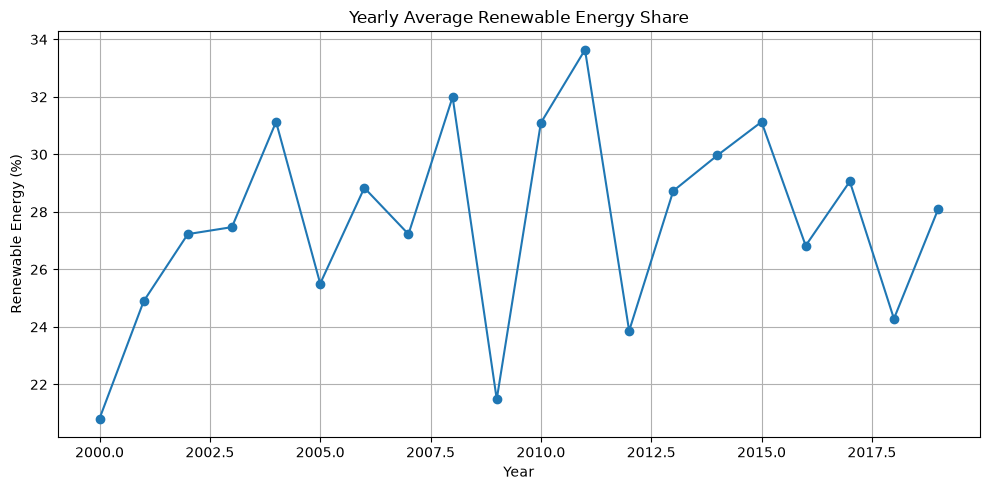

In [52]:
yearly_renewable = (
    df.groupby("Year")["Renewable_Energy (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_renewable["Year"],
    yearly_renewable["Renewable_Energy (%)"],
    marker="o"
)

plt.title(
    "Yearly Average Renewable Energy Share"
)

plt.xlabel("Year")
plt.ylabel("Renewable Energy (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [53]:
severity_energy = (
    df.groupby("Pollution_Severity")[
        "Energy_Recovered (in GWh)"
    ]
    .mean()
    .reindex(["Low", "Medium", "High"])
)

print(
    "Average Energy Recovered by Pollution Severity:"
)

print(severity_energy)

Average Energy Recovered by Pollution Severity:
Pollution_Severity
Low       255.661940
Medium    277.089091
High      248.843433
Name: Energy_Recovered (in GWh), dtype: float64


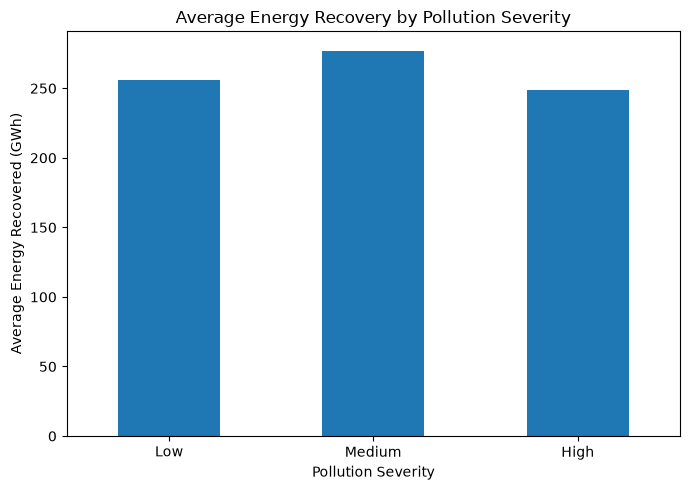

In [54]:
plt.figure(figsize=(7, 5))

severity_energy.plot(
    kind="bar"
)

plt.title(
    "Average Energy Recovery by Pollution Severity"
)

plt.xlabel("Pollution Severity")
plt.ylabel("Average Energy Recovered (GWh)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [55]:
severity_renewable = (
    df.groupby("Pollution_Severity")[
        "Renewable_Energy (%)"
    ]
    .mean()
    .reindex(["Low", "Medium", "High"])
)

print(
    "Average Renewable Energy by Pollution Severity:"
)

print(severity_renewable)

Average Renewable Energy by Pollution Severity:
Pollution_Severity
Low       28.151493
Medium    28.005455
High      27.245224
Name: Renewable_Energy (%), dtype: float64


In [56]:
print("========== FINAL PROJECT FINDINGS ==========\n")

print(
    "1. Pollution severity was divided into Low, Medium, "
    "and High categories."
)

print(
    "\n2. The three pollution indices were excluded from "
    "model predictors to avoid target leakage."
)

print(
    "\n3. KNN selected K =", best_k,
    "using 5-fold cross-validation."
)

print(
    "\n4. Decision Tree selected max_depth =",
    best_tree_depth,
    "and min_samples_split =",
    best_tree_split,
    "using 5-fold cross-validation."
)

print(
    "\n5. Final test-set model performance:"
)

print(comparison.round(3).to_string(index=False))

print(
    "\n6. The energy recovery analysis examines the "
    "relationship between industrial waste, pollution, "
    "renewable energy and recovered energy."
)

========== FINAL PROJECT FINDINGS ==========

1. Pollution severity was divided into Low, Medium, and High categories.

2. The three pollution indices were excluded from model predictors to avoid target leakage.

3. KNN selected K = 7 using 5-fold cross-validation.

4. Decision Tree selected max_depth = 7 and min_samples_split = 5 using 5-fold cross-validation.

5. Final test-set model performance:
                  Model  Accuracy  Precision  Recall  F1 Score
               Baseline     0.333        NaN     NaN       NaN
Multinomial Naive Bayes     0.238      0.221   0.238     0.227
                    KNN     0.357      0.372   0.357     0.358
          Decision Tree     0.262      0.264   0.262     0.262

6. The energy recovery analysis examines the relationship between industrial waste, pollution, renewable energy and recovered energy.


In [57]:
highest_pollution_country = (
    top_10_countries.index[0]
)

highest_pollution_value = (
    top_10_countries.iloc[0]
)

highest_energy_severity = (
    severity_energy.idxmax()
)

highest_energy_value = (
    severity_energy.max()
)

highest_renewable_severity = (
    severity_renewable.idxmax()
)

highest_renewable_value = (
    severity_renewable.max()
)

print("========== ACTIONABLE INSIGHTS ==========\n")

print(
    f"• The country with the highest average pollution "
    f"index in the Top 10 analysis is "
    f"{highest_pollution_country} "
    f"({highest_pollution_value:.2f})."
)

print(
    f"• The pollution severity category with the highest "
    f"average recovered energy is "
    f"{highest_energy_severity} "
    f"({highest_energy_value:.2f} GWh)."
)

print(
    f"• The severity category with the highest average "
    f"renewable energy share is "
    f"{highest_renewable_severity} "
    f"({highest_renewable_value:.2f}%)."
)

print(
    "\n• Industrial waste and energy recovery should be "
    "considered together when planning waste-to-energy "
    "systems."
)

print(
    "• Increasing renewable energy adoption can support "
    "lower-carbon energy strategies."
)

print(
    "• Pollution monitoring can help identify areas "
    "where waste management and energy recovery "
    "systems require greater attention."
)

========== ACTIONABLE INSIGHTS ==========

• The country with the highest average pollution index in the Top 10 analysis is Saint Barthelemy (187.04).
• The pollution severity category with the highest average recovered energy is Medium (277.09 GWh).
• The severity category with the highest average renewable energy share is Low (28.15%).

• Industrial waste and energy recovery should be considered together when planning waste-to-energy systems.
• Increasing renewable energy adoption can support lower-carbon energy strategies.
• Pollution monitoring can help identify areas where waste management and energy recovery systems require greater attention.


In [58]:
output_file = "Global_Pollution_Analysis_Processed.csv"

df.to_csv(
    output_file,
    index=False
)

print(
    "Processed dataset saved as:",
    output_file
)

Processed dataset saved as: Global_Pollution_Analysis_Processed.csv


In [59]:
comparison.to_csv(
    "Model_Comparison_Results.csv",
    index=False
)

knn_cv_results.to_csv(
    "KNN_CV_Results.csv",
    index=False
)

tree_cv_results.to_csv(
    "Decision_Tree_CV_Results.csv",
    index=False
)

print("All result files saved successfully.")

All result files saved successfully.


## Recommendations

Based on the analysis, the following measures can be considered:

- Improve monitoring and management of industrial waste in areas with higher pollution levels.
- Explore suitable waste-to-energy technologies to recover useful energy from industrial waste.
- Increase the use of renewable energy sources to support cleaner energy production.
- Regularly monitor air, water, and soil pollution together instead of focusing on only one pollution type.
- Use pollution and energy-related data to identify areas where environmental management and energy recovery systems can be improved.
- Future studies can include additional environmental and economic variables to improve the classification performance.